# Brain Tumor Segmentation with a 3D U-Net in PyTorch

**Dataset:** [BraTS-Africa](https://www.cancerimagingarchive.net/collection/brats-africa/), Adewole et al., [dataset publication](https://doi.org/10.1148/ryai.240528). The tutorial also provides a [Kaggle copy](https://www.kaggle.com/datasets/aondonamoses/brats-africa).

**Acknowledgments:** My personal adaptation of a tutorial I discovered at Indaba, developed by the Medical Artificial Intelligence Laboratory (Lagos) with SPARK Academy: [original repository](https://github.com/SPARK-Academy-2025/lightweight-brats-tutorial), [guide by Oladele et al.](https://dx.doi.org/10.17504/protocols.io.dm6gpdwmdgzp). I keep the tutorial's workflow and code, with rewritten explanations to reflect my understanding.


In [1]:
import sys
!pip install -q nibabel torch



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## My goal

Build and train a lightweight 3D U-Net on `64 x 64 x 64` patches extracted from the prepared volumes. I use the `glioma_split_data` folder created in [the preprocessing notebook](01_brats_africa_preparation.ipynb). Training can run on a CPU, although it takes time.


## How the 3D U-Net works

The encoder reduces spatial resolution to extract features. The decoder reconstructs a prediction for each voxel, recovering detail through connections from the encoder. Here, internal channel counts range from 16 to 256 to limit model size.

References: [U-Net, Ronneberger et al. (2015)](https://arxiv.org/abs/1505.04597) and [3D U-Net, Cicek et al. (2016)](https://arxiv.org/abs/1606.06650).


## 1. Set up the environment

PyTorch uses the GPU if available, otherwise the CPU. The thread count is limited to leave resources for other tasks.


In [2]:
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import rotate

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("PyTorch", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

torch.set_num_threads(max(os.cpu_count() // 2, 1))

PyTorch 2.13.0+cpu
Device: cpu


In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Set the data path

`DATA_ROOT` should point to `glioma_split_data`, containing the `train`, `val`, and `test` subfolders. On Colab, if the files are on Drive, mount it and adjust this path.


In [4]:
import sys
DATA_ROOT = "glioma_split_data"

In [5]:
NUM_CLASSES = 4
PATCH_SIZE = (64, 64, 64)
BATCH_SIZE = 2
EPOCHS = 100
LEARNING_RATE = 0.001

## 2. Build the U-Net

PyTorch tensors use the shape `(batch, channels, depth, height, width)` here. The model takes four MRI channels and produces four scores per voxel.


In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Dropout3d(dropout),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

`ConvBlock` combines two 3D convolutions, ReLU activations, and dropout. Layers are defined in `__init__` and applied in `forward`.


In [7]:
class UNet3D(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, 16, 0.1)
        self.enc2 = ConvBlock(16, 32, 0.1)
        self.enc3 = ConvBlock(32, 64, 0.2)
        self.enc4 = ConvBlock(64, 128, 0.2)
        self.bottleneck = ConvBlock(128, 256, 0.3)

        self.pool = nn.MaxPool3d(2)

        self.up4 = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(256, 128, 0.2)
        self.up3 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(128, 64, 0.2)
        self.up2 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(64, 32, 0.1)
        self.up1 = nn.ConvTranspose3d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16, 0.1)

        self.out = nn.Conv3d(16, num_classes, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        c2 = self.enc2(self.pool(c1))
        c3 = self.enc3(self.pool(c2))
        c4 = self.enc4(self.pool(c3))
        c5 = self.bottleneck(self.pool(c4))

        u4 = self.dec4(torch.cat([self.up4(c5), c4], dim=1))
        u3 = self.dec3(torch.cat([self.up3(u4), c3], dim=1))
        u2 = self.dec2(torch.cat([self.up2(u3), c2], dim=1))
        u1 = self.dec1(torch.cat([self.up1(u2), c1], dim=1))

        return self.out(u1)

In `forward`, the encoder stages reduce resolution and the decoder stages restore it. `torch.cat(..., dim=1)` joins features from the two branches. The final convolution produces **logits**, without softmax; the loss handles the required conversion.


In [8]:
model = UNet3D(in_channels=4, num_classes=NUM_CLASSES).to(device)

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", "{:,}".format(total_params))

Total parameters: 5,646,260


I count the trainable parameters to measure the size of the network.


## 3. Load patches

The `Dataset` prepares individual examples, and the `DataLoader` groups them into batches. Extracting patches reduces training memory requirements.


In [9]:
def extract_patch(image, mask, patch_size):
    shape = image.shape[:3]
    x = np.random.randint(0, max(shape[0] - patch_size[0], 1))
    y = np.random.randint(0, max(shape[1] - patch_size[1], 1))
    z = np.random.randint(0, max(shape[2] - patch_size[2], 1))
    return (image[x:x + patch_size[0], y:y + patch_size[1], z:z + patch_size[2], :],
            mask[x:x + patch_size[0], y:y + patch_size[1], z:z + patch_size[2]])


def gamma_correction(image, gamma):
    return np.clip(image ** gamma, 0, 1)


def augment(image, mask):
    angle = np.random.uniform(-15, 15)
    image = rotate(image, angle, axes=(0, 1), reshape=False, mode="reflect")
    mask = rotate(mask, angle, axes=(0, 1), reshape=False, mode="reflect", order=0)

    if np.random.rand() > 0.5:
        image, mask = np.flip(image, axis=0), np.flip(mask, axis=0)
    if np.random.rand() > 0.5:
        image, mask = np.flip(image, axis=1), np.flip(mask, axis=1)

    image = np.clip(image * np.random.uniform(0.9, 1.1), 0, 1)

    if np.random.rand() > 0.5:
        image = np.clip(image + np.random.normal(0, 0.02, image.shape), 0, 1)
    if np.random.rand() > 0.5:
        image = gamma_correction(image, np.random.uniform(0.8, 1.2))

    return image, mask

`extract_patch` crops the same region from the image and mask. Geometric transformations are shared, while intensity changes apply only to the image.


In [10]:
class GliomaPatches(Dataset):
    def __init__(self, img_dir, mask_dir, patch_size, is_training):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.patch_size = patch_size
        self.is_training = is_training
        self.names = sorted(f for f in os.listdir(img_dir) if f.endswith(".npy"))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]
        image = np.load(os.path.join(self.img_dir, name)).astype(np.float32)
        mask_name = name.replace("image_", "mask_")
        mask = np.load(os.path.join(self.mask_dir, mask_name))
        mask = np.argmax(mask, axis=-1).astype(np.int64)

        image, mask = extract_patch(image, mask, self.patch_size)
        if self.is_training:
            image, mask = augment(image, mask)

        image = np.ascontiguousarray(np.transpose(image, (3, 0, 1, 2)), dtype=np.float32)
        mask = np.ascontiguousarray(mask, dtype=np.int64)

        return torch.from_numpy(image), torch.from_numpy(mask)

In `__getitem__`, `argmax` converts the one-hot mask back to class indices. The image changes from `(D, H, W, C)` to `(C, D, H, W)` to match the model input format.


In [11]:
train_set = GliomaPatches(os.path.join(DATA_ROOT, "train", "images"),
                          os.path.join(DATA_ROOT, "train", "masks"),
                          PATCH_SIZE, is_training=True)
val_set = GliomaPatches(os.path.join(DATA_ROOT, "val", "images"),
                        os.path.join(DATA_ROOT, "val", "masks"),
                        PATCH_SIZE, is_training=False)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

print("Training volumes:  ", len(train_set))
print("Validation volumes:", len(val_set))

Training volumes:   66
Validation volumes: 13


In [12]:
sample_x, sample_y = next(iter(train_loader))
print("Image batch:", tuple(sample_x.shape), sample_x.dtype)
print("Mask batch: ", tuple(sample_y.shape), sample_y.dtype)

Image batch: (2, 4, 64, 64, 64) torch.float32
Mask batch:  (2, 64, 64, 64) torch.int64


An image batch has shape `(batch, 4, 64, 64, 64)`. Masks have shape `(batch, 64, 64, 64)` and contain integer labels.


## 4. Define the loss and Dice score

Background dominates the volumes, making accuracy alone uninformative. I combine Dice loss with cross-entropy and use the Dice score to monitor overlap.


In [13]:
def dice_loss(logits, target, num_classes, smooth=1e-6):
    probs = F.softmax(logits, dim=1)
    target_onehot = F.one_hot(target, num_classes).permute(0, 4, 1, 2, 3).float()

    dims = (0, 2, 3, 4)
    intersection = torch.sum(probs * target_onehot, dims)
    cardinality = torch.sum(probs + target_onehot, dims)
    dice = (2. * intersection + smooth) / (cardinality + smooth)
    return 1 - dice.mean()


cross_entropy = nn.CrossEntropyLoss()


def total_loss(logits, target):
    return dice_loss(logits, target, NUM_CLASSES) + cross_entropy(logits, target)

Dice loss compares probabilities with one-hot masks, class by class. I minimize `1 - Dice` and add cross-entropy, calculated from logits and integer labels.


In [14]:
@torch.no_grad()
def dice_score(logits, target, num_classes, smooth=1e-6):
    preds = torch.argmax(logits, dim=1)
    scores = []
    for c in range(num_classes):
        p = (preds == c).float()
        t = (target == c).float()
        intersection = (p * t).sum()
        union = p.sum() + t.sum()
        scores.append(((2. * intersection + smooth) / (union + smooth)).item())
    return float(np.mean(scores))

The metric uses `argmax` predictions and averages Dice over all four classes, **including background**. `@torch.no_grad()` avoids computing gradients for this measurement.


## 5. Configure optimization

I use NAdam and a scheduler that halves the learning rate when validation loss plateaus. The training loop also clips the gradient norm.


In [15]:
optimizer = torch.optim.NAdam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5, min_lr=1e-5)

## 6. Write one training epoch

For each batch: predict, compute the loss, backpropagate, clip gradients, and update the weights. Validation only measures performance.


In [16]:
def run_epoch(loader, training):
    model.train(training)
    total = 0.0
    dice_total = 0.0
    n = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = total_loss(logits, masks)

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total += loss.item()
        dice_total += dice_score(logits, masks, NUM_CLASSES)
        n += 1

    return total / max(n, 1), dice_total / max(n, 1)

`run_epoch` handles both modes. `model.train(training)` switches dropout on or off, and gradients are computed only during training.


## 7. Train the model

I save the weights with the lowest validation loss. Training stops after ten epochs without improvement. I can start with `EPOCHS = 2` or `3` to check the workflow, but that is not enough to assess model quality.


In [17]:
os.makedirs("saved_model", exist_ok=True)
checkpoint_path = "saved_model/3d_unet_pytorch.pt"

best_val = float("inf")
patience, wait = 10, 0
history = []

start = time.time()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_dice = run_epoch(train_loader, training=True)
    val_loss, val_dice = run_epoch(val_loader, training=False)
    scheduler.step(val_loss)

    history.append({"loss": train_loss, "val_loss": val_loss,
                    "dice_score": train_dice, "val_dice_score": val_dice})
    print("Epoch {:3d}  train loss {:.4f}  val loss {:.4f}  train dice {:.4f}  val dice {:.4f}".format(
        epoch, train_loss, val_loss, train_dice, val_dice))

    if val_loss < best_val:
        best_val = val_loss
        wait = 0
        torch.save(model.state_dict(), checkpoint_path)
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping at epoch", epoch)
            break

minutes = (time.time() - start) / 60
# print("Training finished in {:.1f} minutes".format(minutes))

os.makedirs("model_history", exist_ok=True)
pd.DataFrame(history).to_csv("model_history/pytorch_history.csv", index=False)

Epoch   1  train loss 1.5939  val loss 1.2594  train dice 0.2225  val dice 0.2989
Epoch   2  train loss 1.3485  val loss 1.5040  train dice 0.2549  val dice 0.2215
Epoch   3  train loss 1.9973  val loss 1.3869  train dice 0.2467  val dice 0.2559
Epoch   4  train loss 1.3306  val loss 1.1921  train dice 0.2720  val dice 0.3669
Epoch   5  train loss 1.2716  val loss 1.7232  train dice 0.2801  val dice 0.2234
Epoch   6  train loss 1.2213  val loss 1.3971  train dice 0.2565  val dice 0.3368
Epoch   7  train loss 1.2058  val loss 1.1014  train dice 0.2607  val dice 0.2899
Epoch   8  train loss 1.2470  val loss 1.1724  train dice 0.3072  val dice 0.3358
Epoch   9  train loss 1.2269  val loss 1.3009  train dice 0.3103  val dice 0.2473
Epoch  10  train loss 49.0155  val loss 1.2264  train dice 0.3223  val dice 0.2398
Epoch  11  train loss 8.6521  val loss 1.4642  train dice 0.2897  val dice 0.3741
Epoch  12  train loss 1.1923  val loss 1.1988  train dice 0.2910  val dice 0.2893
Epoch  13  trai

## 8. Read the learning curves

I look for decreasing loss and increasing Dice. A growing gap between training and validation may indicate overfitting.


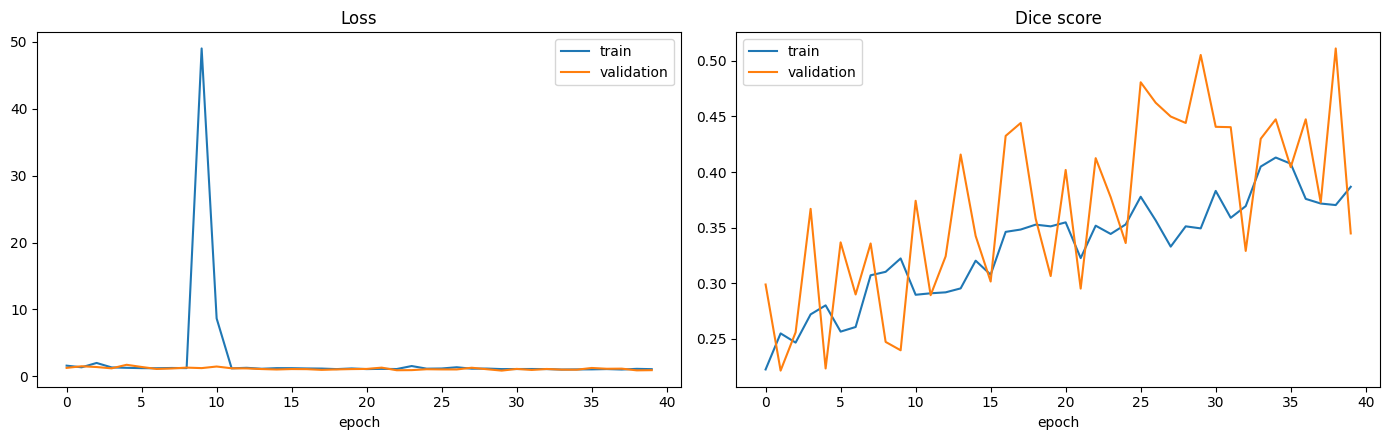

In [18]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(hist["loss"], label="train")
axes[0].plot(hist["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(hist["dice_score"], label="train")
axes[1].plot(hist["val_dice_score"], label="validation")
axes[1].set_title("Dice score")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Evaluate the best weights

I reload the saved model and measure Dice on several batches of random patches, first on validation and then on test data. This sampled score can vary and is not an exhaustive evaluation of full volumes.


In [19]:
model.load_state_dict(torch.load(checkpoint_path))
model.eval()


@torch.no_grad()
def evaluate(img_dir, mask_dir, n_batches=10):
    dataset = GliomaPatches(img_dir, mask_dir, PATCH_SIZE, is_training=False)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)
    scores = []
    it = iter(loader)
    for _ in range(n_batches):
        try:
            images, masks = next(it)
        except StopIteration:
            it = iter(loader)
            images, masks = next(it)
        logits = model(images.to(device))
        scores.append(dice_score(logits, masks.to(device), NUM_CLASSES))
    return float(np.mean(scores))

In [20]:
val_dice = evaluate(os.path.join(DATA_ROOT, "val", "images"),
                    os.path.join(DATA_ROOT, "val", "masks"))
test_dice = evaluate(os.path.join(DATA_ROOT, "test", "images"),
                     os.path.join(DATA_ROOT, "test", "masks"))

print("Validation Dice: {:.4f}".format(val_dice))
print("Test Dice:       {:.4f}".format(test_dice))

Validation Dice: 0.4240
Test Dice:       0.3458


## 10. Inspect a prediction

I now predict on an entire `128 x 128 x 128` test volume and compare a slice with the reference mask. This requires more memory than patches. The dimensions remain compatible with the four downsampling stages.


In [21]:
from matplotlib.colors import ListedColormap

SEG_CMAP = ListedColormap(["#00000000", "#e41a1c", "#4daf4a", "#377eb8"])


def show_labels(ax, label_slice, background=None, alpha=0.6):
    if background is not None:
        ax.imshow(np.rot90(background), cmap="gray")
    ax.imshow(np.rot90(np.ma.masked_where(label_slice == 0, label_slice)),
              cmap=SEG_CMAP, vmin=0, vmax=3, interpolation="nearest", alpha=alpha)
    ax.axis("off")

In [22]:
test_img_dir = os.path.join(DATA_ROOT, "test", "images")
test_mask_dir = os.path.join(DATA_ROOT, "test", "masks")
example = sorted(f for f in os.listdir(test_img_dir) if f.endswith(".npy"))[0]

test_img = np.load(os.path.join(test_img_dir, example)).astype(np.float32)
test_mask = np.argmax(np.load(os.path.join(
    test_mask_dir, example.replace("image_", "mask_"))), axis=-1)

with torch.no_grad():
    x = torch.from_numpy(np.ascontiguousarray(
        np.transpose(test_img, (3, 0, 1, 2)))).unsqueeze(0).to(device)
    logits = model(x)
    pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

z = int(np.argmax((test_mask > 0).sum(axis=(0, 1))))
print("Showing", example, "at slice", z)

Showing image_11.npy at slice 31


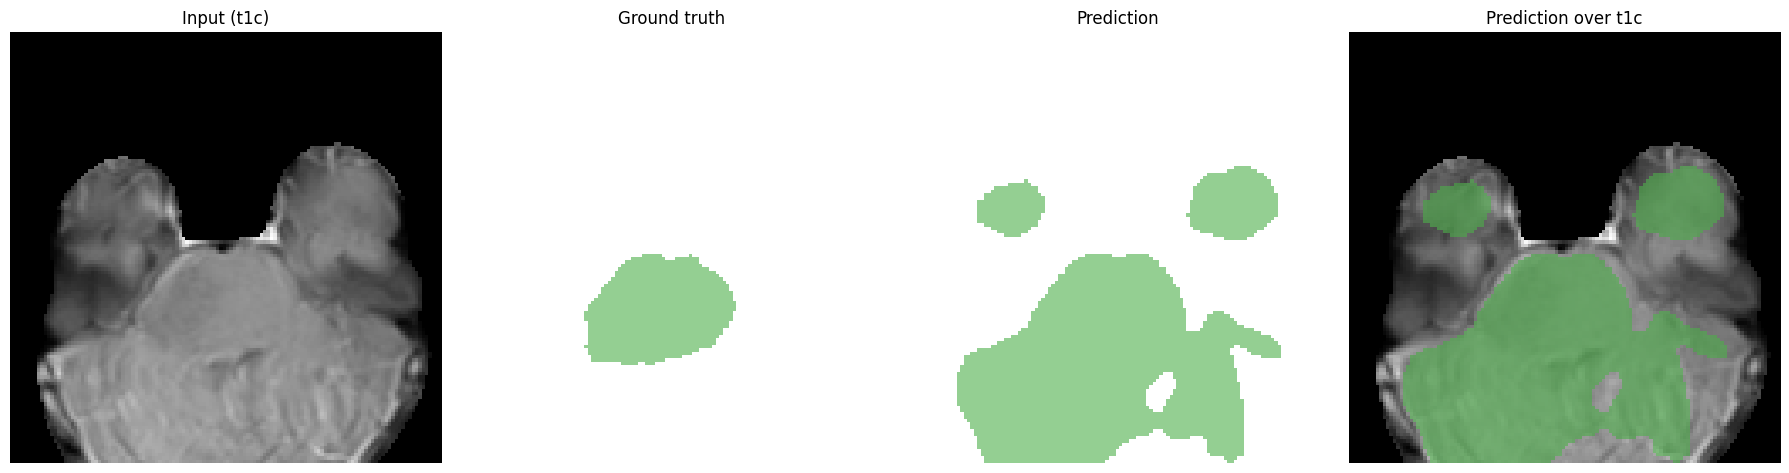

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(np.rot90(test_img[:, :, z, 1]), cmap="gray")
axes[0].set_title("Input (t1c)")
axes[0].axis("off")

show_labels(axes[1], test_mask[:, :, z])
axes[1].set_title("Ground truth")

show_labels(axes[2], pred[:, :, z])
axes[2].set_title("Prediction")

show_labels(axes[3], pred[:, :, z], background=test_img[:, :, z, 1])
axes[3].set_title("Prediction over t1c")

plt.tight_layout()
plt.show()

The colors keep the same meaning: red for necrotic core, green for edema, and blue for enhancing tumor. Alongside Dice, I inspect localization and any missed or extra regions.

## What I take from this

This pipeline connects preprocessed volumes to voxel-level segmentation through patch loading, a 3D U-Net, optimization, and evaluation. Model and patch sizes limit memory requirements, while scores and visual checks help assess the results.
